In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from helper_files.maoa_plate_loader import *
from helper_files.mea_feats_analysis import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings


warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


In [3]:
#open pickle
with open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'rb') as file:
    big_df = pickle.load(file)

In [4]:
#add experiment group
big_df["experiment"] = big_df.apply(
    lambda row: assign_experiment(row["plate_name"], row["recording_date"]),
    axis=1
)

In [5]:
#remove day sept 26th (bad recording)

#remove bad experiment 
# Convert recording_date safely
big_df["recording_date"] = pd.to_datetime(big_df["recording_date"], errors="coerce")

# Remove all recordings from Sept 26, 2025
remove_date = pd.to_datetime("2025-09-26")
big_df = big_df[big_df["recording_date"] != remove_date]

#### Mutant (c3, c71, c90), WT (c12, c30, c54) and GM

In [6]:
#Remove lines we are not using 
REMOVALS = {
    "MAOA1":{"H9", "C12", "C3", "C54","C71"},
    "MAOA2":{"H9", "C12", "C3", "C54","C71"},
    "MAOA3":{"H9", "C12", "C3", "C54","C71"},
    "MAOA72": {"C12", "C3", "C54", "C71"},
    "MAOA76": {"C12", "C3", "C54", "C71"},
    "MAOA77": {"C12", "C3", "C54", "C71"},
}

In [7]:
big_df = remove_clones_by_plate(big_df, REMOVALS)

Removed 516 rows based on plate-specific clone removal.


In [8]:
big_df

,well,firing_rate_stats_hz,burst_rate_stats_hz,network_event_rate_hz,synchrony_index,electrodes,firing_rate_vector_hz,burst_rate_vector_hz,recording_date,recording_date_str,plate_name,cell_line,organoid_age_days,spike_list_path,experiment
0,A2,"[1.4391208230357608, 1.6648439676442284]","[0.09436092897565711, 0.09586305971365496]",0.124031,0.022132,"[A2_11, A2_12, A2_13, A2_14, A2_15, A2_16, A2_...","[3.015680429868851, 0.0006597419448411399, 0.0...","[0.19066542205908946, nan, nan, nan, 0.0032987...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
1,A3,"[0.4052027312243695, 0.5762036681376207]","[0.018160265113258748, 0.024168885783248578]",0.003299,0.000282,"[A3_11, A3_12, A3_13, A3_14, A3_15, A3_16, A3_...","[nan, 0.0006597419448411399, 0.000659741944841...","[nan, nan, nan, nan, 0.00791690333809368, nan,...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
2,A4,"[0.5015034617690537, 0.8086074177045918]","[0.035769487183343544, 0.05082674212974362]",0.056738,0.003155,"[A4_11, A4_12, A4_13, A4_14, A4_15, A4_16, A4_...","[0.13260813091306914, 0.0006597419448411399, 0...","[0.008576645282934819, nan, nan, nan, 0.003298...",2025-04-14,04.14.2025,MAOA2,C90,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
3,B2,"[1.821286102520696, 3.2362072623431377]","[0.1274676415928486, 0.11408226907420285]",0.148442,0.013659,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.0013194838896822799, 3.5289596629552578, 0....","[nan, 0.20188103512138883, nan, nan, 0.0936833...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
4,B3,"[0.7793130012355004, 1.3467926472630483]","[0.058214372561458665, 0.07832226183330862]",0.078509,0.001454,"[B3_11, B3_12, B3_13, B3_14, B3_15, B3_16, B3_...","[5.249566655100951, 0.0006597419448411399, nan...","[0.17747058316226666, nan, nan, 0.085106710884...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
931,A3,"[0.05701119431773227, 0.1535796905411747]","[0.032265241228589356, 0.03379079821952257]",0.000000,0.051877,"[A3_11, A3_12, A3_13, A3_14, A3_15, A3_16, A3_...","[0.07891625880113576, 0.01890702033777211, 0.0...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,C90,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
932,A4,"[0.004241748910561047, 0.009775569618114778]","[nan, nan]",0.000000,0.232831,"[A4_11, A4_12, A4_13, A4_14, A4_15, A4_16, A4_...","[0.0008220443625118308, nan, 0.000822044362511...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
933,B3,"[0.18866972022675382, 0.5198453411082501]","[0.03605251704159029, 0.0311337640259423]",0.000000,0.067674,"[B3_11, B3_12, B3_13, B3_14, B3_15, B3_16, B3_...","[1.6054526399856057, 0.0008220443625118308, 0....","[0.027127463962890418, nan, nan, nan, 0.023839...",2025-10-30,10.30.2025,MAOA76,C90,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
934,B4,"[0.010609510053668317, 0.045617147944364]","[0.01808497597526028, 0.0]",0.000000,-0.001633,"[B4_11, B4_12, B4_13, B4_14, B4_15, B4_16, B4_...","[0.004932266175070985, 0.0008220443625118308, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3


### Exp 3 analysis for Paper Figure


### RUNNING ANALYSIS FOR Exp3 ###
Plates included: ['MAOA72' 'MAOA77' 'MAOA76']

### DRAWING PLATE MAPS ###
 → Plotting MAOA72


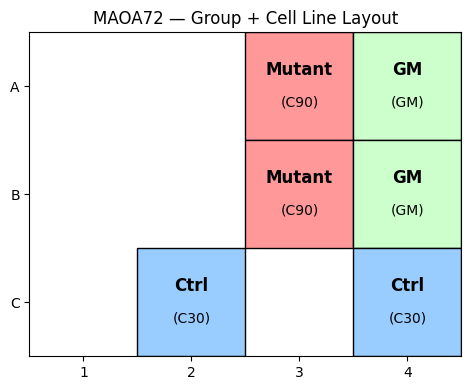

 → Plotting MAOA77


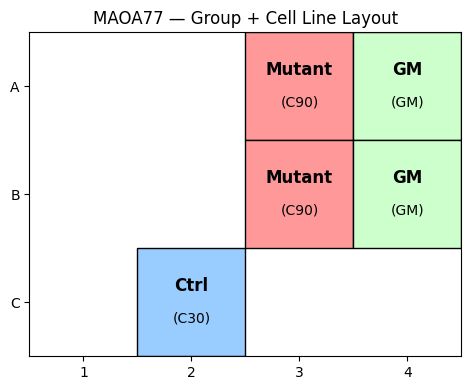

 → Plotting MAOA76


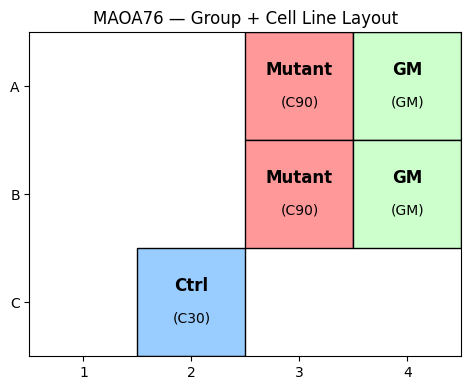


### GENERATING FEATURE PLOTS — CELL LINES ###
 → Plotting firing (cell lines)

=== Plotting Experiment Exp3 ===


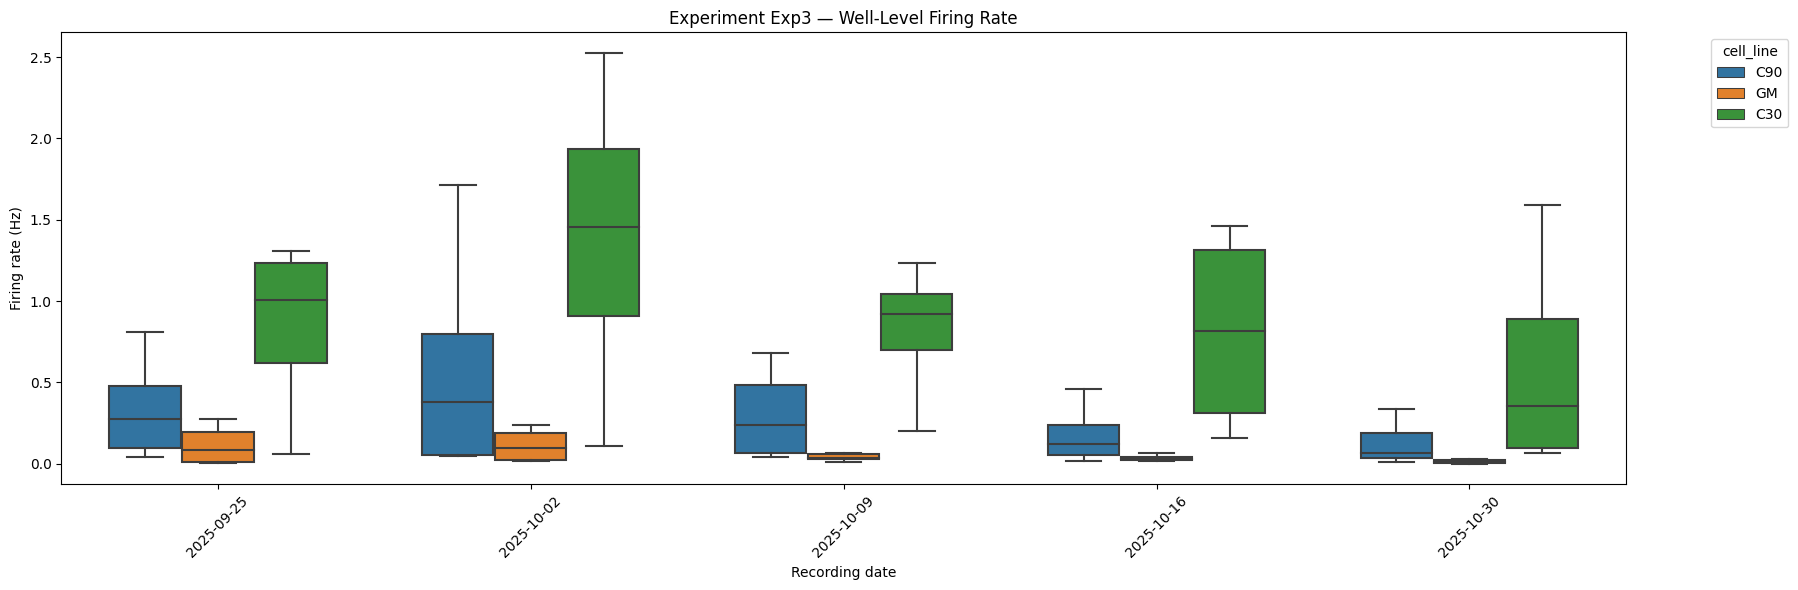

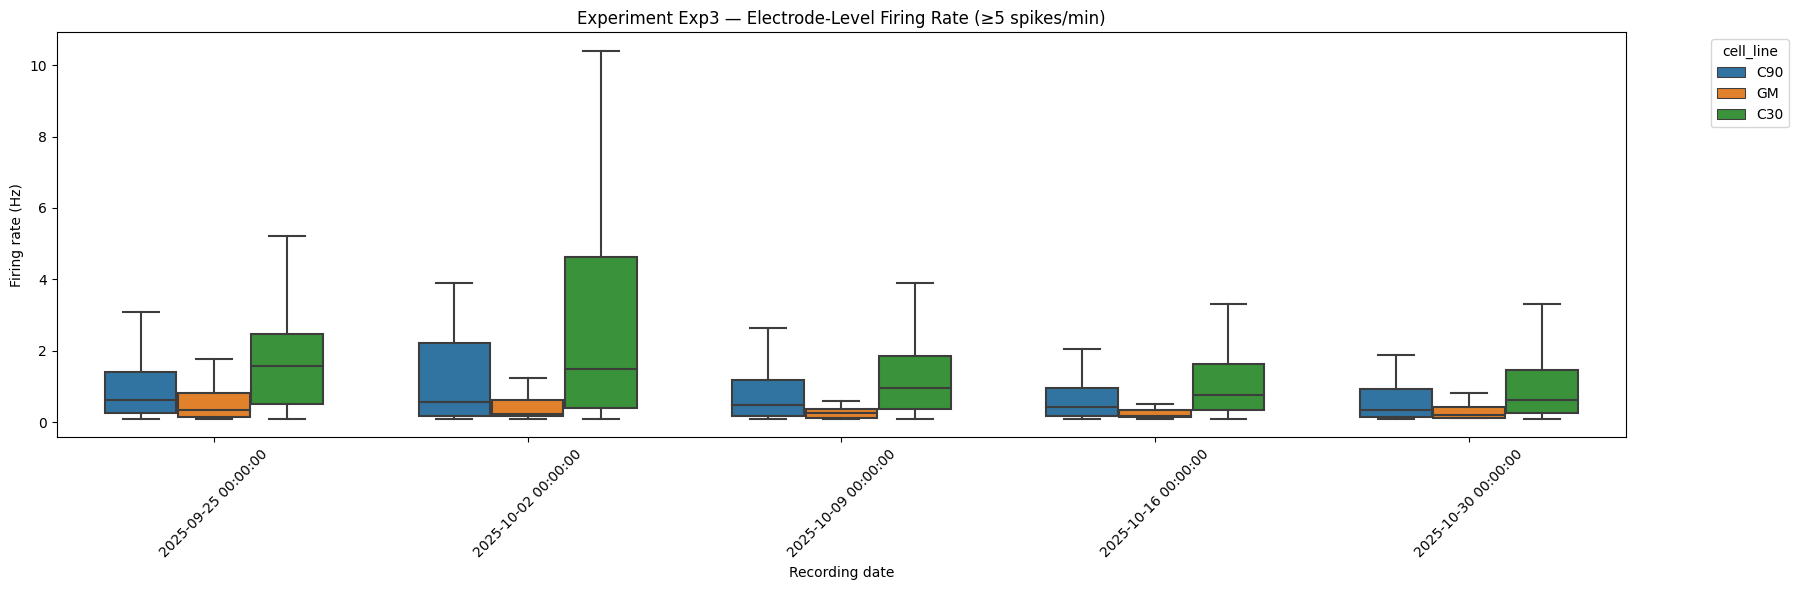

 → Plotting burst (cell lines)

=== Plotting Experiment Exp3 ===


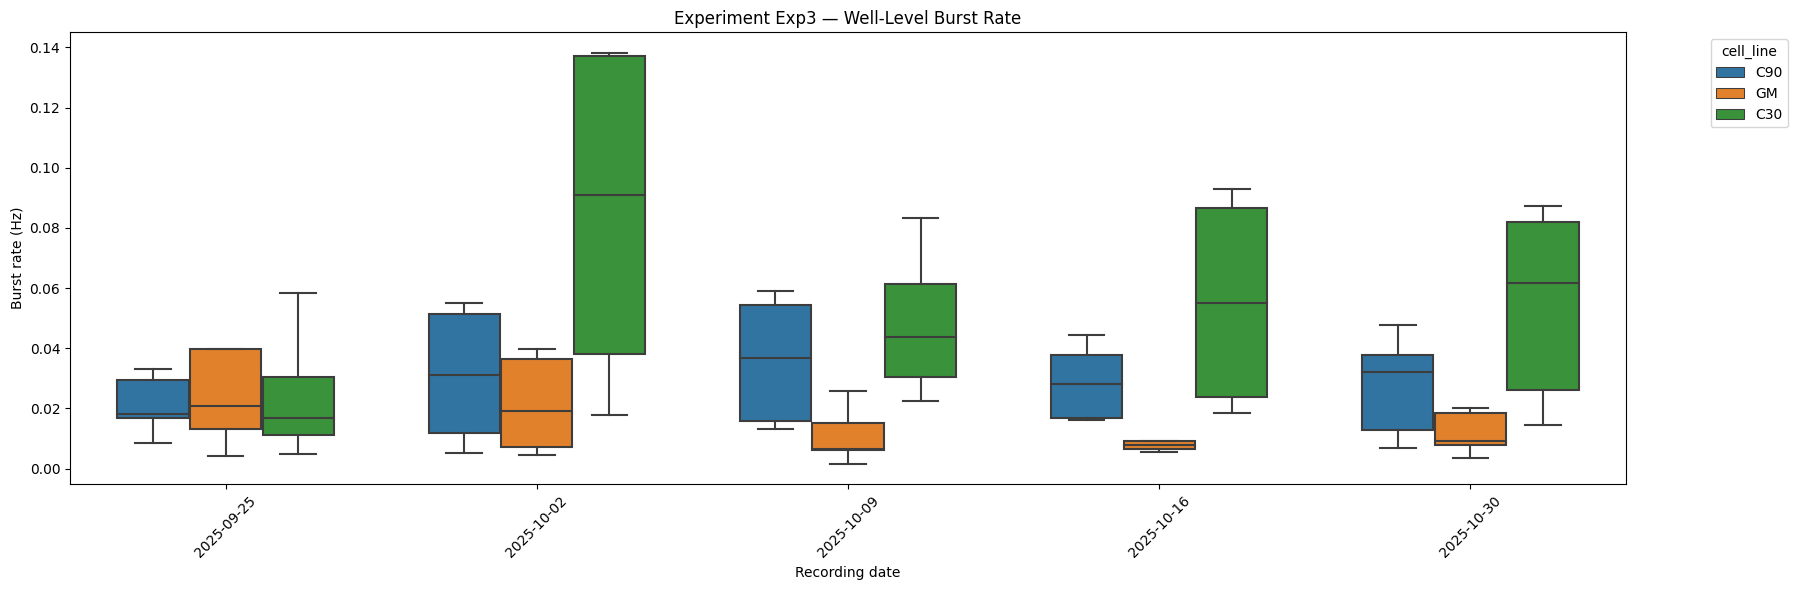

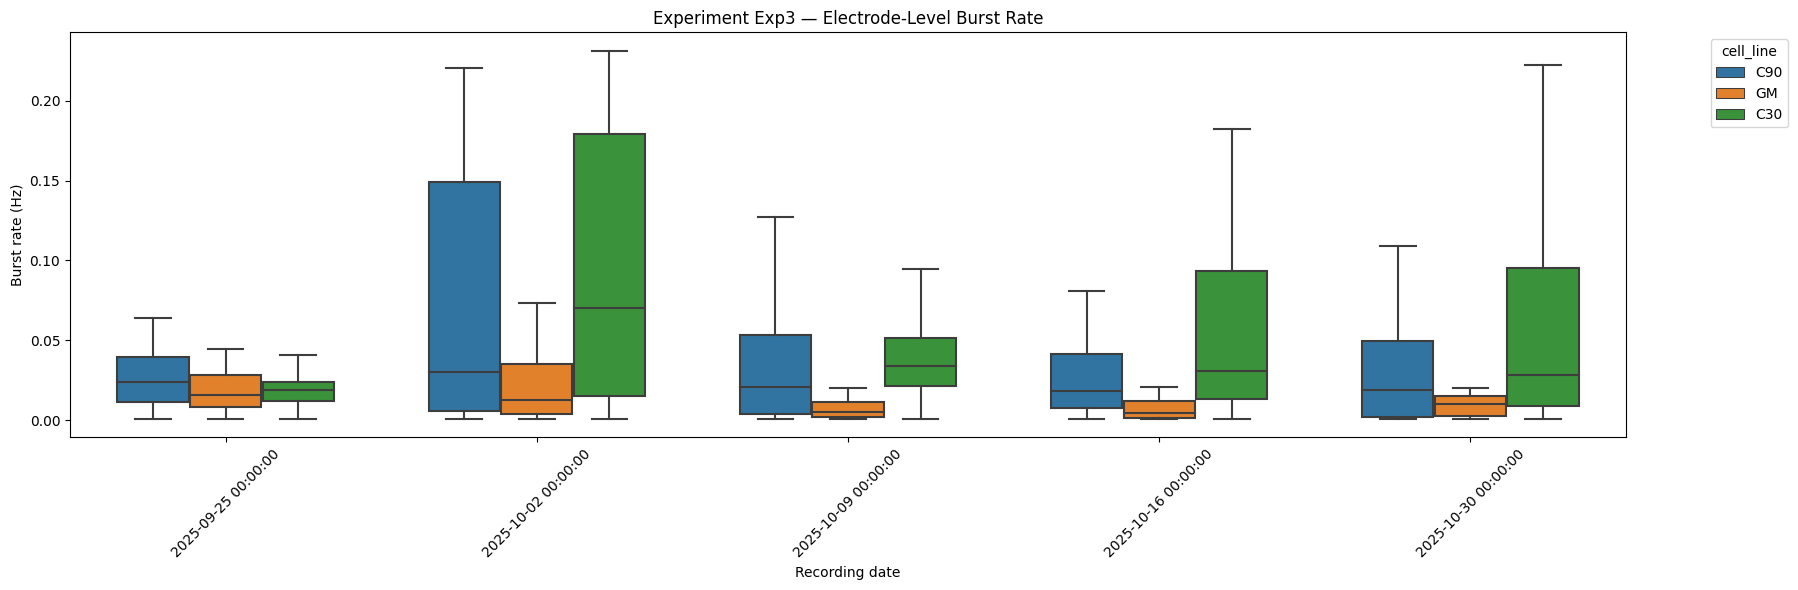

 → Plotting network (cell lines)

=== Plotting Experiment Exp3 ===


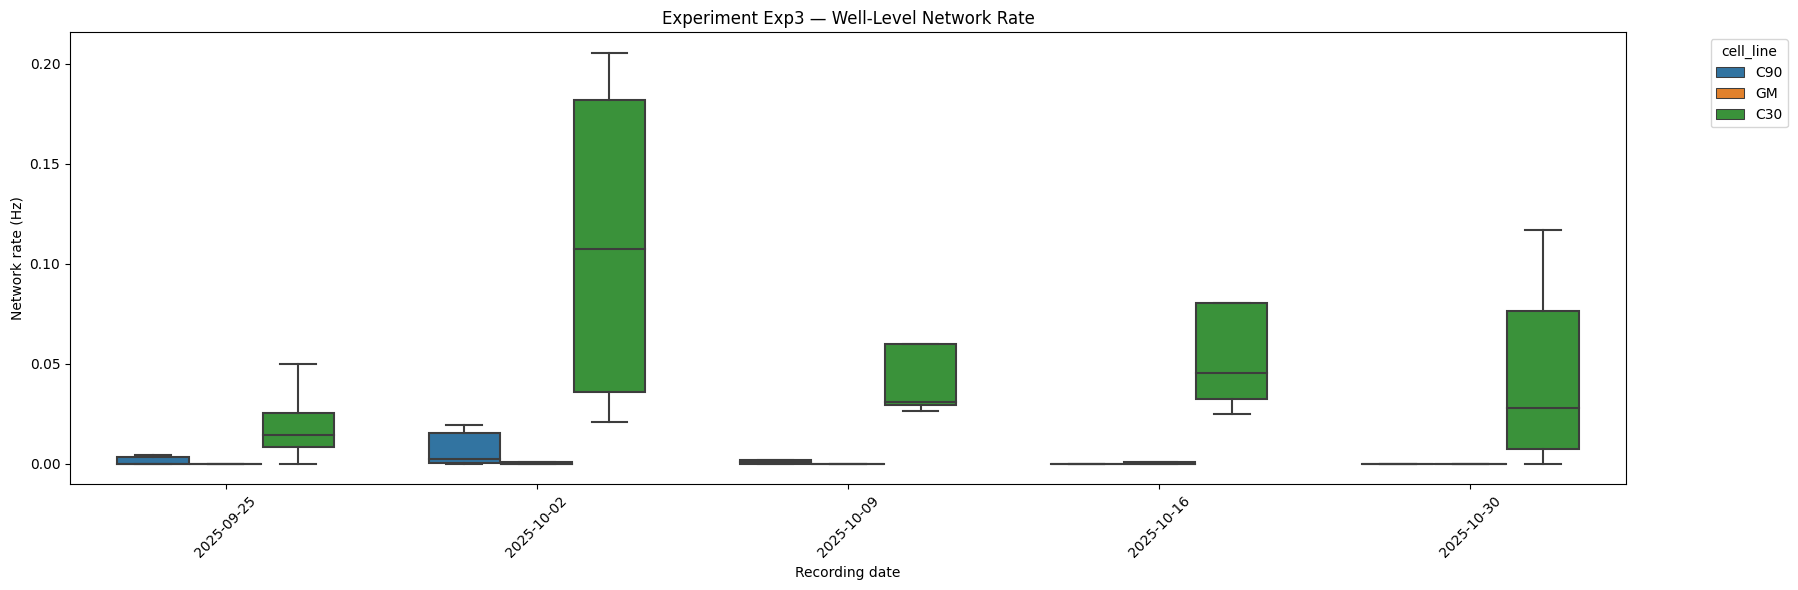

 → Plotting synchrony (cell lines)

=== Plotting Experiment Exp3 ===


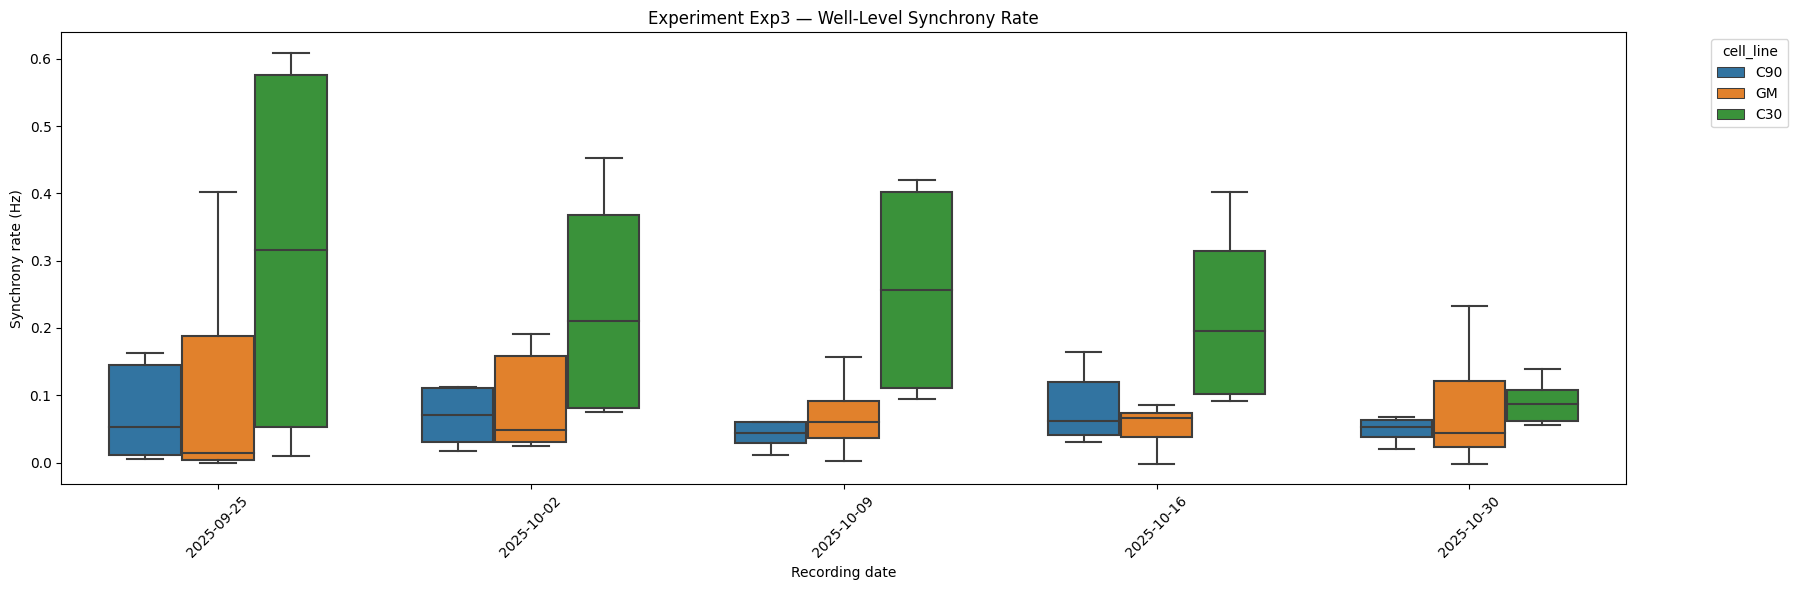


### GENERATING FEATURE PLOTS — GROUPS ###
 → Plotting firing (groups)

=== Plotting Experiment Exp3 ===


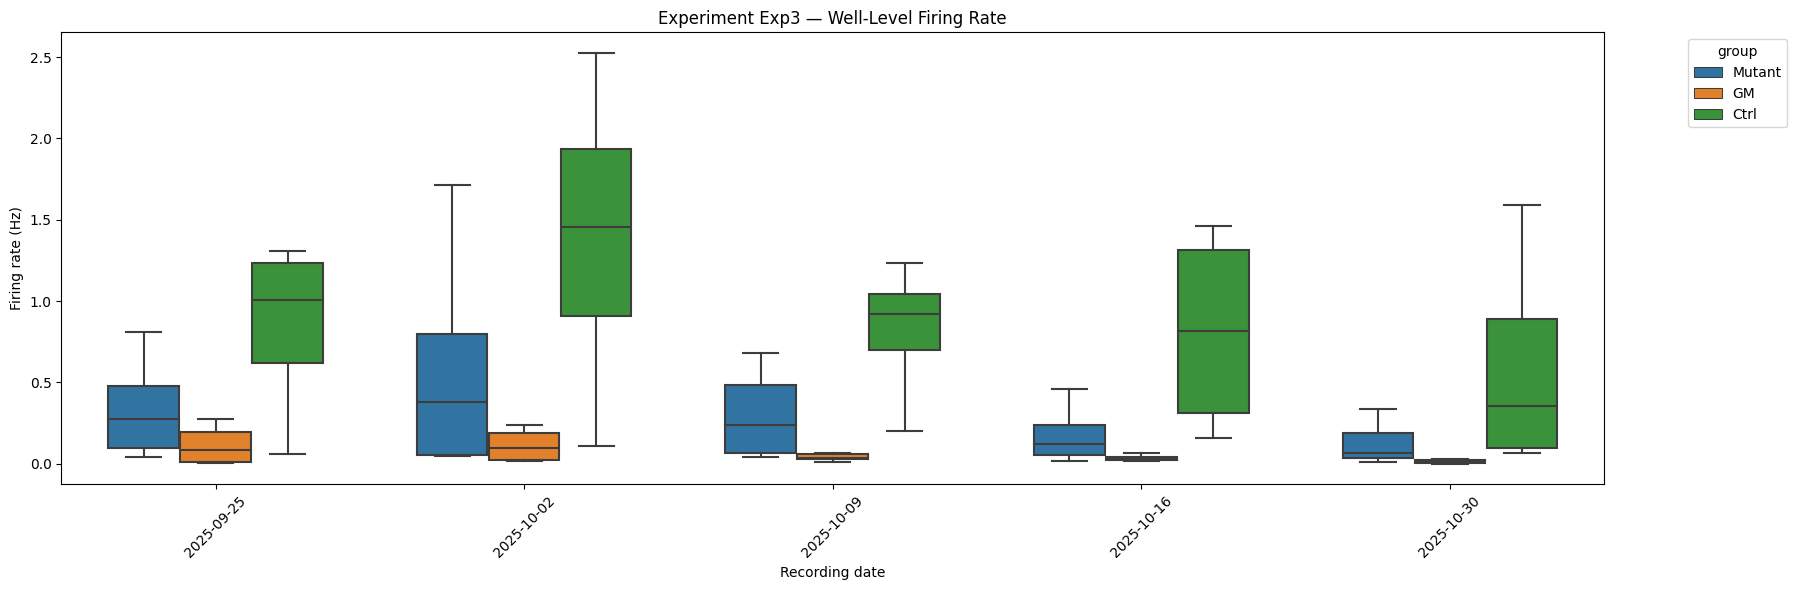

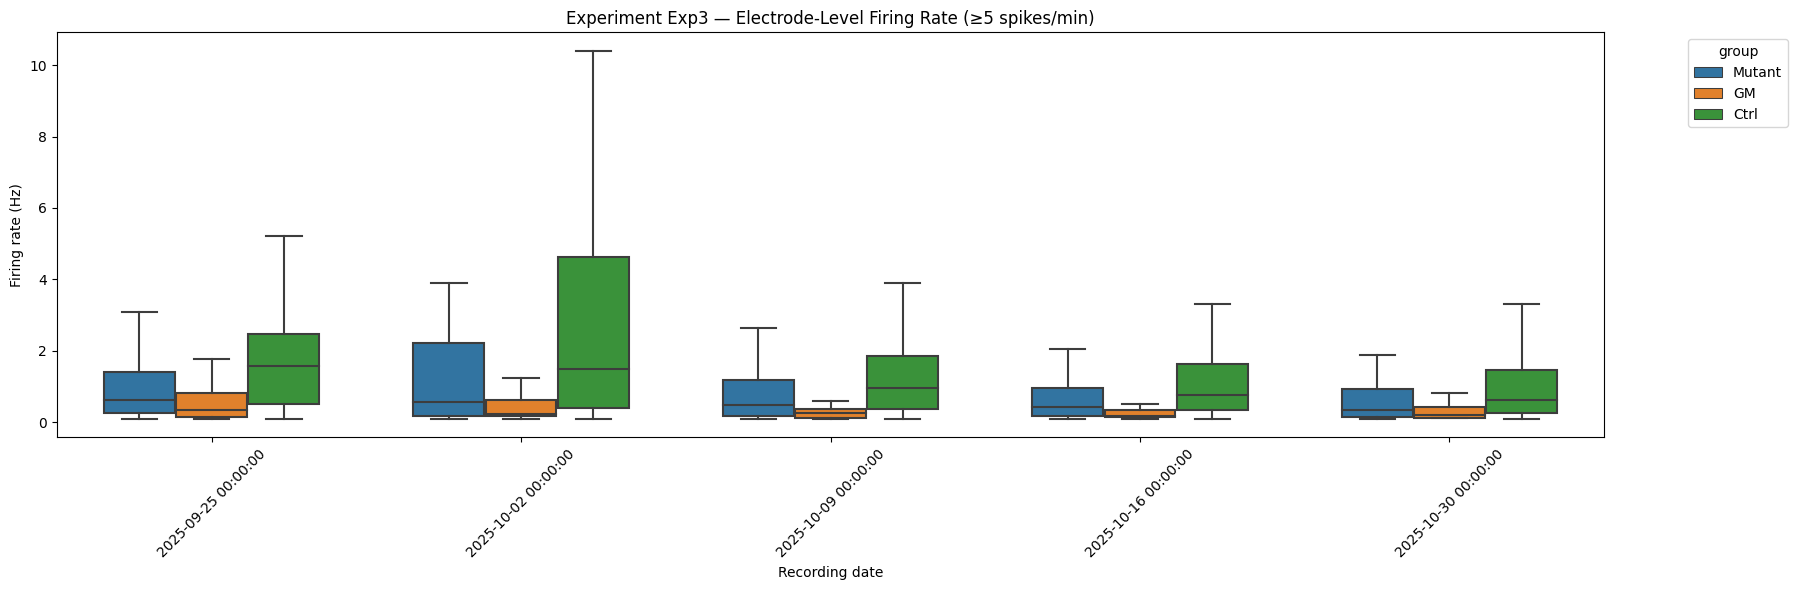

 → Plotting burst (groups)

=== Plotting Experiment Exp3 ===


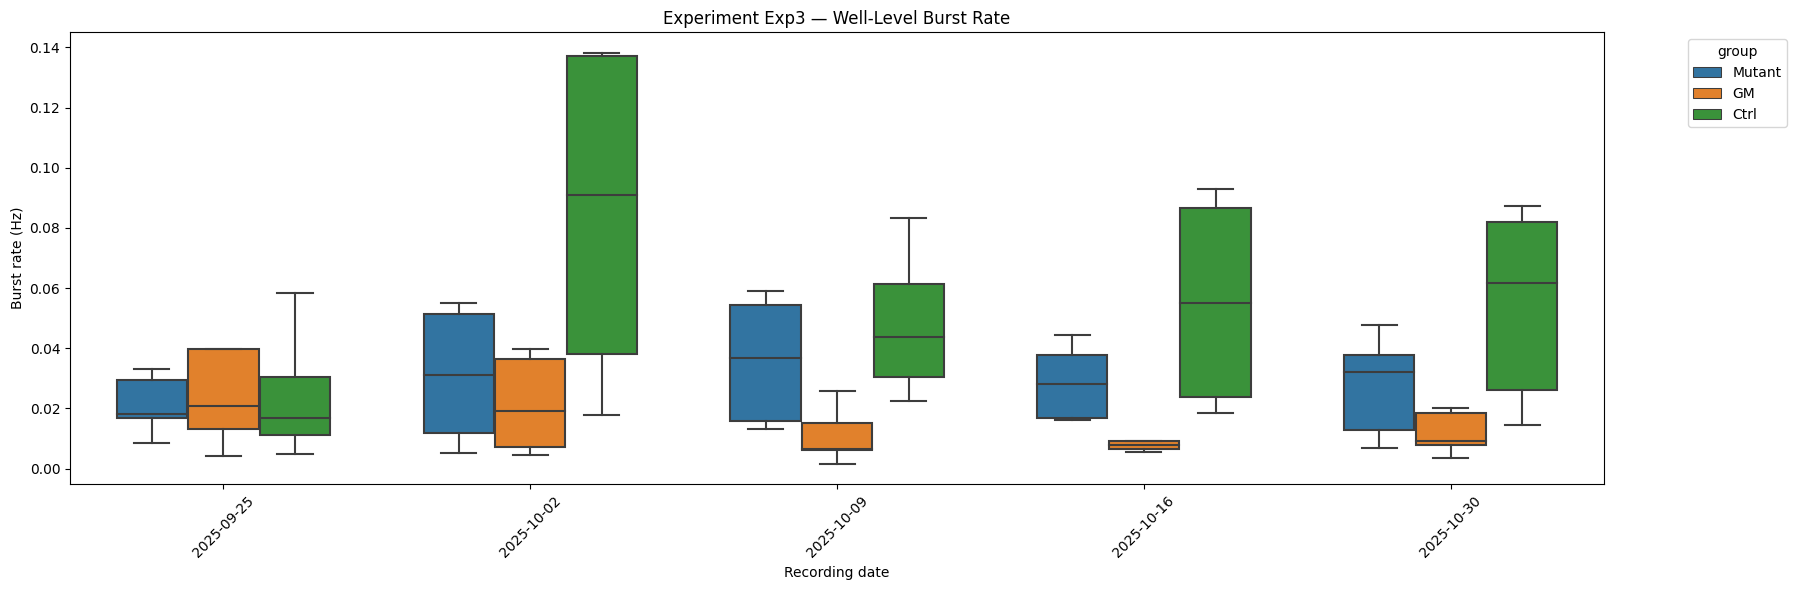

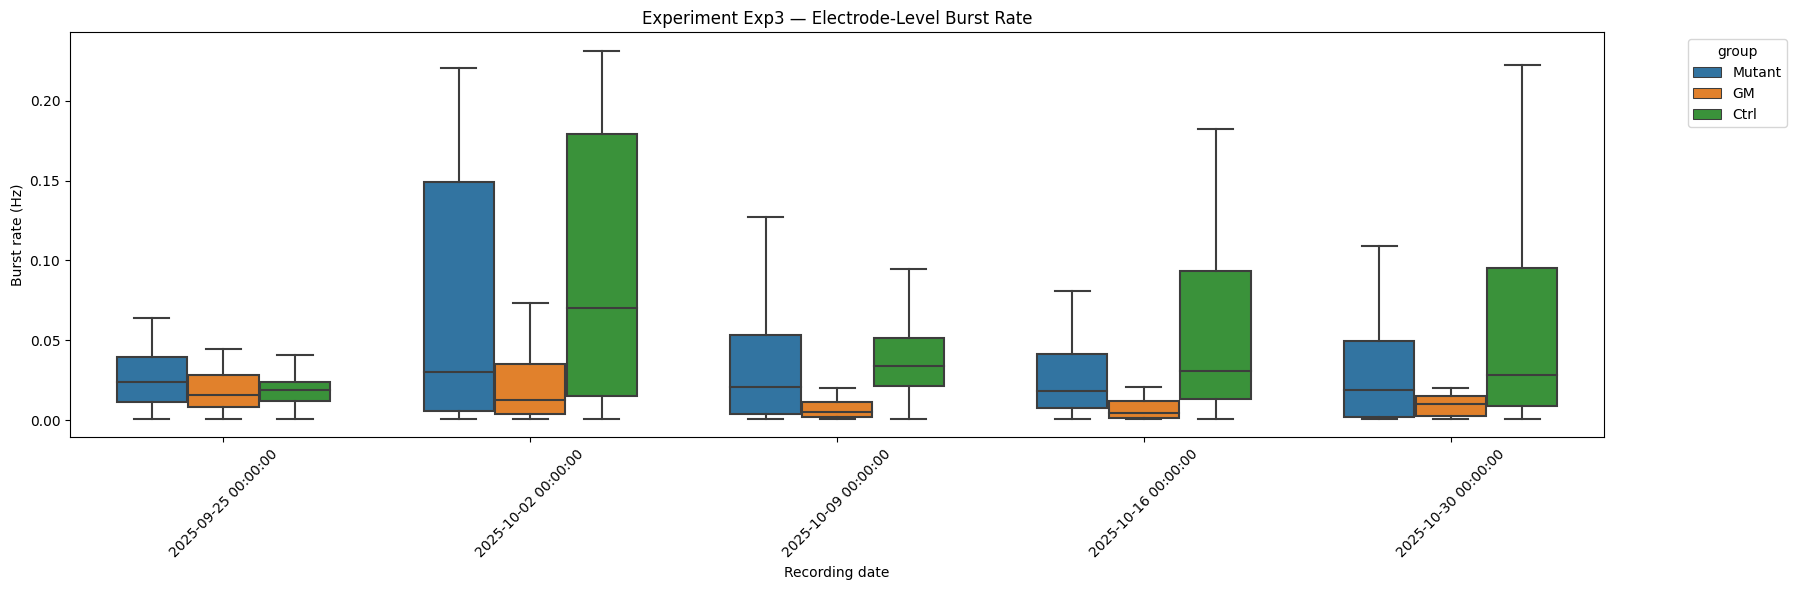

 → Plotting network (groups)

=== Plotting Experiment Exp3 ===


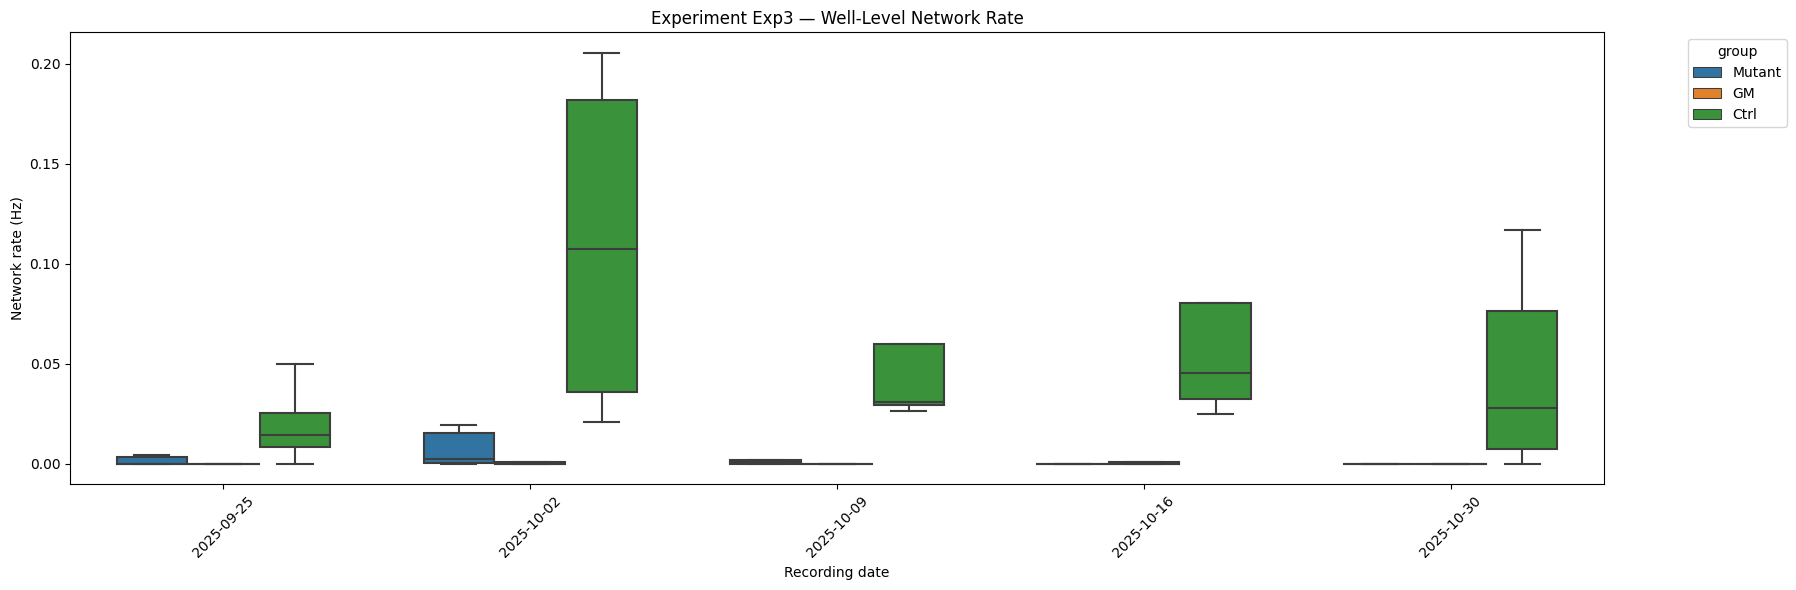

 → Plotting synchrony (groups)

=== Plotting Experiment Exp3 ===


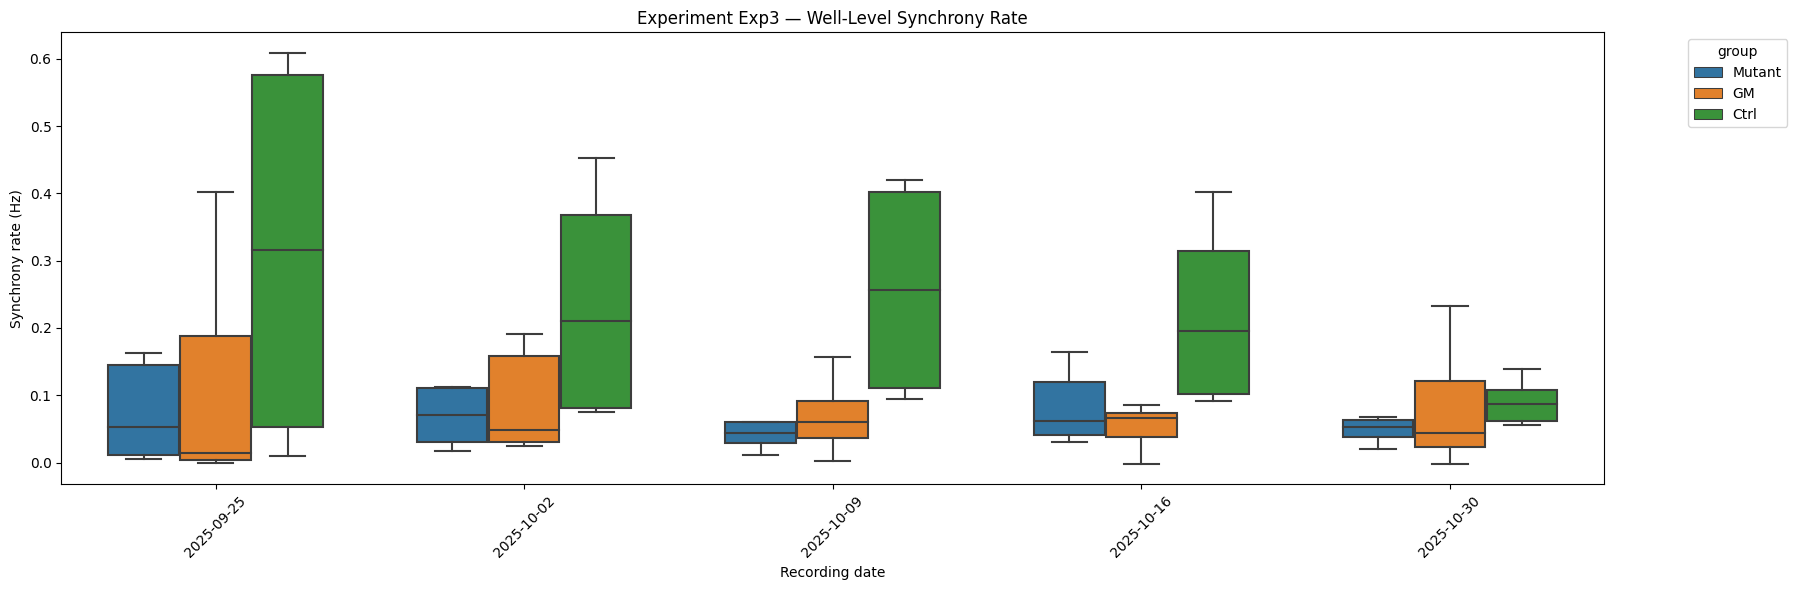


### RUNNING STATISTICS — CELL LINES ###

===== CELL LINE STATS: FIRING =====
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.

  WELL-LEVEL POST-HOC t-tests:
  group1 group2     mean1     mean2  difference         t     p_raw     p_fmt  \
0    C30    C90  0.827228  0.263386    0.563842  3.869307  0.000511  0.000511   
1    C30     GM  0.827228  0.057527    0.769701  5.730063  0.000007  0.000007   
2    C90     GM  0.263386  0.057527    0.205859  3.486003  0.001251  0.001251   

     p_bonf p_bonf_fmt  
0  0.001534   0.001534  
1  0.000022   0.000022  
2  0.003753   0.003753  

===== CELL LINE STATS: BURST =====

  WELL-LEVEL POST-HOC t-tests:
  group1 group2     mean1     mean2  difference         t     p_raw     p_fmt  \
0    C30    C90  0.053857  0.030333    0.023523  2.719318  0.01039

In [9]:
results_exp1 = run_full_mea_analysis(
    big_df,
    experiment='Exp3',
    assign_groups=True,
    use_group_for_plate_map=True,
    double_label=True
)


In [101]:
def run_mea_analysis_for_figure(df, experiment, unit="days", palette=MAOA_FIGURE_PALETTE, threshold_spikes_per_min=5):

    # 1. Pre-process and Genotype Assign
    df_exp = df[df["experiment"] == experiment].copy()
    def assign_genotype(line):
        if line in {"C30", "C12c"}: return "Xa:WT/Xi:MUT"
        if line in {"C90", "C90m"}: return "Xa:MUT/Xi:WT"
        if line in {"GM", "MAOA/B−/Y"}: return "MAOA/B−/Y"
        return "other"
    
    df_exp["group"] = df_exp["cell_line"].apply(assign_genotype)
    
    # 2. Age Calculation (August 12, 2025 baseline)
    ref_date = pd.to_datetime("2025-08-12")
    df_exp["recording_date"] = pd.to_datetime(df_exp["recording_date"])
    df_exp["age_days"] = (df_exp["recording_date"] - ref_date).dt.days + 180
    df_exp["time_val"] = (df_exp["age_days"] / 30.44).round(1) if unit == "months" else df_exp["age_days"]

    for feat in ["firing", "burst", "network", "synchrony"]:
        print(f"\n{'='*40}\nFEATURE: {feat.upper()}\n{'='*40}")
        plot_figure_boxplots_for_paper(df_exp, feat, MAOA_FIGURE_PALETTE, PLOT_ORDER, unit)
        stats = run_comprehensive_stats(df_exp, feat, unit)
        print("\nTrajectory ANOVA (Interaction):\n", stats["anova"])
        print("\nTime-Point Comparisons:\n", stats["table"].to_string(index=False))




In [134]:


def plot_figure_boxplots_for_paper(df, feature, palette, order, unit="months", threshold_spikes_per_min=5):
    df = df.copy()
    threshold_hz = threshold_spikes_per_min / 60.0
    
    # 1. Feature Mapping
    if feature == "firing": 
        df["plot_val"] = df["firing_rate_stats_hz"].str[0]
        ylabel = "Firing Rate (Hz)"
        elec_key = "firing_rate_vector_hz"
    elif feature == "burst": 
        df["plot_val"] = df["burst_rate_stats_hz"].str[0]
        ylabel = "Burst Rate (Hz)"
        elec_key = "burst_rate_vector_hz"
    elif feature == "network": 
        df["plot_val"] = df["network_event_rate_hz"]
        ylabel = "Network Rate (Hz)"
    elif feature == "synchrony": 
        df["plot_val"] = df["synchrony_index"]
        ylabel = "Synchrony Index"

    xlabel = f"Age ({unit.capitalize()})"

    def draw_trajectory_panel(data, y_col, title):
        data = data.dropna(subset=[y_col]).sort_values("age_days")
        
        # --- Stats: Trajectory Interaction ---
        try:
            model = smf.ols(f"{y_col} ~ C(group) * C(time_val)", data=data).fit()
            p_interact = anova_lm(model, typ=2).loc["C(group):C(time_val)", "PR(>F)"]
            traj_summary = f"Trajectory: {get_sig_stars(p_interact)}"
            
            # --- Stats: Post-hoc with FULL Group Names ---
            posthoc_text = ""
            if p_interact < 0.05:
                comp = mc.MultiComparison(data[y_col], data["group"])
                post_hoc = comp.tukeyhsd()
                ph_df = pd.DataFrame(data=post_hoc.summary().data[1:], columns=post_hoc.summary().data[0])
                
                sigs = []
                for _, row in ph_df.iterrows():
                    if row['p-adj'] < 0.05:
                        # Uses the literal full names from the dataframe
                        sigs.append(f"{row['group1']} vs {row['group2']}: {get_sig_stars(row['p-adj'])}")
                posthoc_text = "\n".join(sigs)
        except:
            traj_summary = "Trajectory: N/A"
            posthoc_text = ""

        plt.figure(figsize=(12, 7))
        sns.set_style("ticks")
        
        # A. Boxplots (Bold) & Stripplot (Sheer)
        ax = sns.boxplot(data=data, x="time_val", y=y_col, hue="group", hue_order=order,
                         palette=palette, showfliers=False, width=0.6,
                         boxprops=dict(alpha=0.8, edgecolor='black'))
        
        sns.stripplot(data=data, x="time_val", y=y_col, hue="group", hue_order=order,
                      palette=palette, dodge=True, alpha=0.15, jitter=0.2, size=3, legend=False)

        # B. Regression Lines (Dashed)
        time_points = sorted(data["time_val"].unique())
        x_map = {val: i for i, val in enumerate(time_points)}
        data['x_idx'] = data['time_val'].map(x_map)
        
        for g in order:
            sub = data[data["group"] == g]
            if len(sub) > 2:
                sns.regplot(data=sub, x="x_idx", y=y_col, scatter=False, color=palette[g],
                            truncate=True, line_kws={"ls":"--", "lw":2.5})

        # C. Trajectory Info Box (Upper Right)
        info_str = f"{traj_summary}\n{posthoc_text}".strip()
        plt.text(0.97, 0.95, info_str, transform=ax.transAxes, fontsize=9, fontweight='bold', 
                 verticalalignment='top', horizontalalignment='right',
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='gray'))

        plt.title(title, fontsize=14, fontweight='bold')
        plt.ylabel(ylabel)
        plt.xlabel(xlabel)
        plt.legend(title="Genotype", bbox_to_anchor=(1.05, 0.7), loc='upper left', frameon=False)
        sns.despine()
        plt.tight_layout()
        plt.show()

    # Generate Panels
    draw_trajectory_panel(df, "plot_val", f"Well-Level {feature.capitalize()} Trajectory")

    if feature in ["firing", "burst"]:
        expanded = []
        for _, row in df.iterrows():
            for v in row[elec_key]:
                expanded.append({"group": row["group"], "time_val": row["time_val"], 
                                 "age_days": row["age_days"], "v": v})
        elec_df = pd.DataFrame(expanded).dropna()
        if feature == "firing": elec_df = elec_df[elec_df["v"] >= threshold_hz]
        
        draw_trajectory_panel(elec_df, "v", f"Electrode-Level {feature.capitalize()} Trajectory")


In [135]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
import statsmodels.stats.multicomp as mc
from scipy.stats import linregress, ttest_ind

def run_comprehensive_stats(df, feature, unit="months"):
    df = df.copy()
    time_col = "time_val"
    
    if feature == "firing": df["well_value"] = df["firing_rate_stats_hz"].str[0]
    elif feature == "burst": df["well_value"] = df["burst_rate_stats_hz"].str[0]
    elif feature == "network": df["well_value"] = df["network_event_rate_hz"]
    elif feature == "synchrony": df["well_value"] = df["synchrony_index"]

    df = df.dropna(subset=["well_value", "group", "time_val"])

    # A. TRAJECTORY ANOVA (Interaction)
    model = smf.ols(f"well_value ~ C(group) * C({time_col})", data=df).fit()
    anova_traj = anova_lm(model, typ=2)
    
    # B. TIME-POINT ANALYSIS TABLE
    timepoint_results = []
    for time in sorted(df[time_col].unique()):
        sub = df[df[time_col] == time]
        if len(sub["group"].unique()) > 1:
            m_pt = smf.ols("well_value ~ C(group)", data=sub).fit()
            p_anova = anova_lm(m_pt, typ=2).loc["C(group)", "PR(>F)"]
            res = {"Time": time, "ANOVA_p": p_anova}
            
            if p_anova < 0.05:
                # Tukey Post-hoc
                comp = mc.MultiComparison(sub["well_value"], sub["group"])
                ph = comp.tukeyhsd()
                ph_df = pd.DataFrame(data=ph.summary().data[1:], columns=ph.summary().data[0])
                for _, row in ph_df.iterrows():
                    res[f"{row['group1']} vs {row['group2']} (p-adj)"] = row['p-adj']
            timepoint_results.append(res)

    return {"anova": anova_traj, "table": pd.DataFrame(timepoint_results)}

In [136]:
def _format_p(p, ndigits=6):
    """Format p-values as decimals with fixed number of digits."""
    if p is None or np.isnan(p):
        return ""
    return f"{p:.{ndigits}f}"


def _clean_anova_table(anova):
    """Rename columns, add p-formatted column."""
    cleaned = anova.rename(
        columns={
            "sum_sq": "SS",
            "df": "DF",
            "F": "F_statistic",
            "PR(>F)": "p_value"
        }
    )
    cleaned["p_formatted"] = cleaned["p_value"].apply(_format_p)
    return cleaned


In [137]:
def get_sig_stars(p):
    if p < 0.001: return "***"
    if p < 0.01: return "**"
    if p < 0.05: return "*"
    return "ns"

In [138]:
# Updated palette using the specific genetic strings as keys
MAOA_FIGURE_PALETTE = {
    "Xa:WT/Xi:MUT": "#9C899C", # Pink/grey (Ctrl)
    "Xa:MUT/Xi:WT": "#EAC3EB", # Light pink (Mut)
    "MAOA/B−/Y":    "#E980C0"  # Dark pink (GM)
}


PLOT_ORDER = ["Xa:WT/Xi:MUT", "Xa:MUT/Xi:WT", "MAOA/B−/Y"]


FEATURE: FIRING


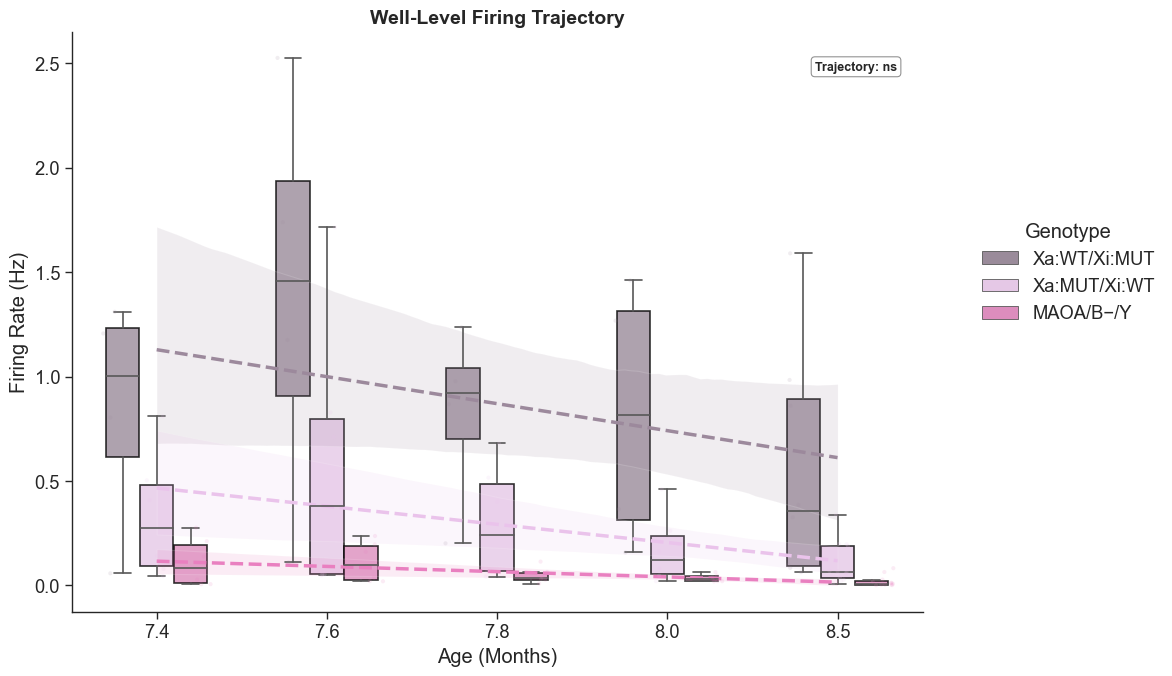

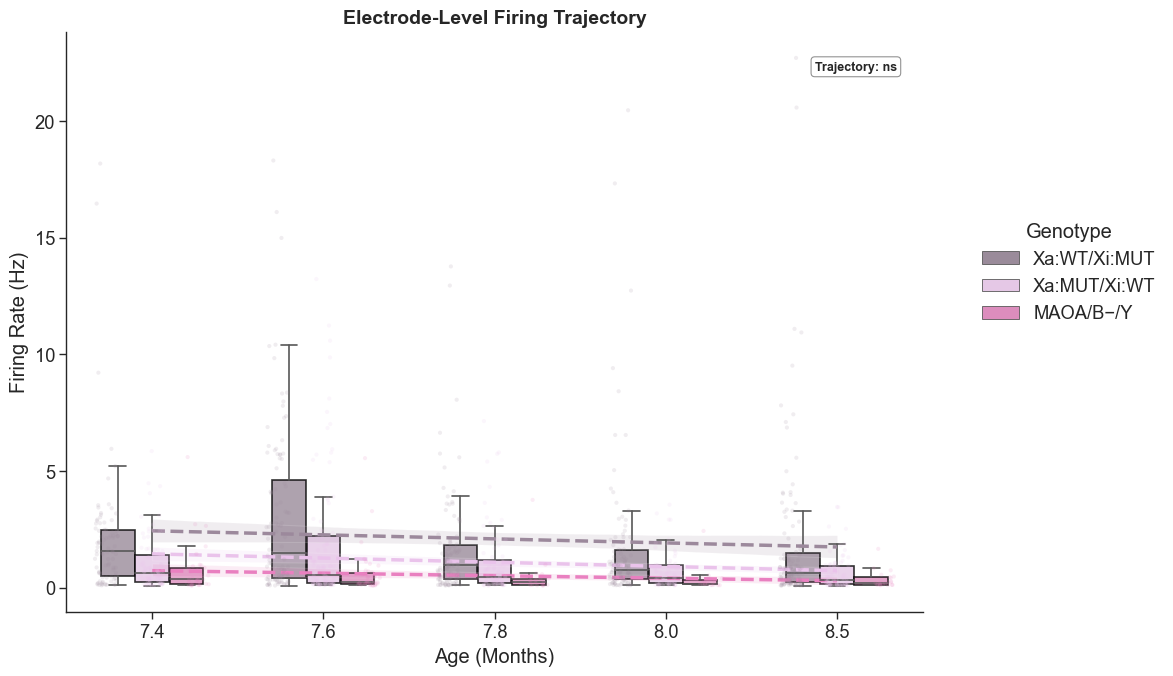


Trajectory ANOVA (Interaction):
                          sum_sq    df          F        PR(>F)
C(group)               8.765318   2.0  31.134685  9.320358e-11
C(time_val)            1.933233   4.0   3.433452  1.208469e-02
C(group):C(time_val)   0.937174   8.0   0.832218  5.768818e-01
Residual              11.401926  81.0        NaN           NaN

Time-Point Comparisons:
  Time  ANOVA_p  MAOA/B−/Y vs Xa:MUT/Xi:WT (p-adj)  MAOA/B−/Y vs Xa:WT/Xi:MUT (p-adj)  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT (p-adj)
  7.4 0.016213                             0.5144                             0.0131                                0.0828
  7.6 0.028082                             0.4567                             0.0222                                0.1563
  7.8 0.002547                             0.2836                             0.0019                                0.0268
  8.0 0.007505                             0.7530                             0.0073                                0.0245
  8.5 0.00

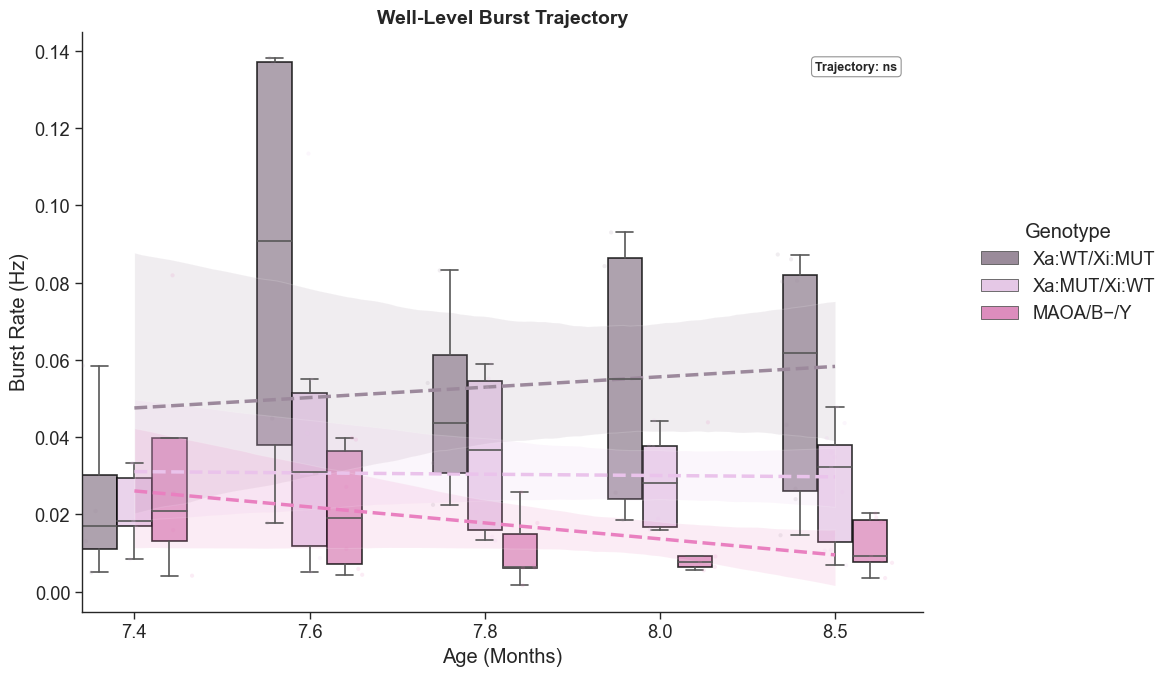

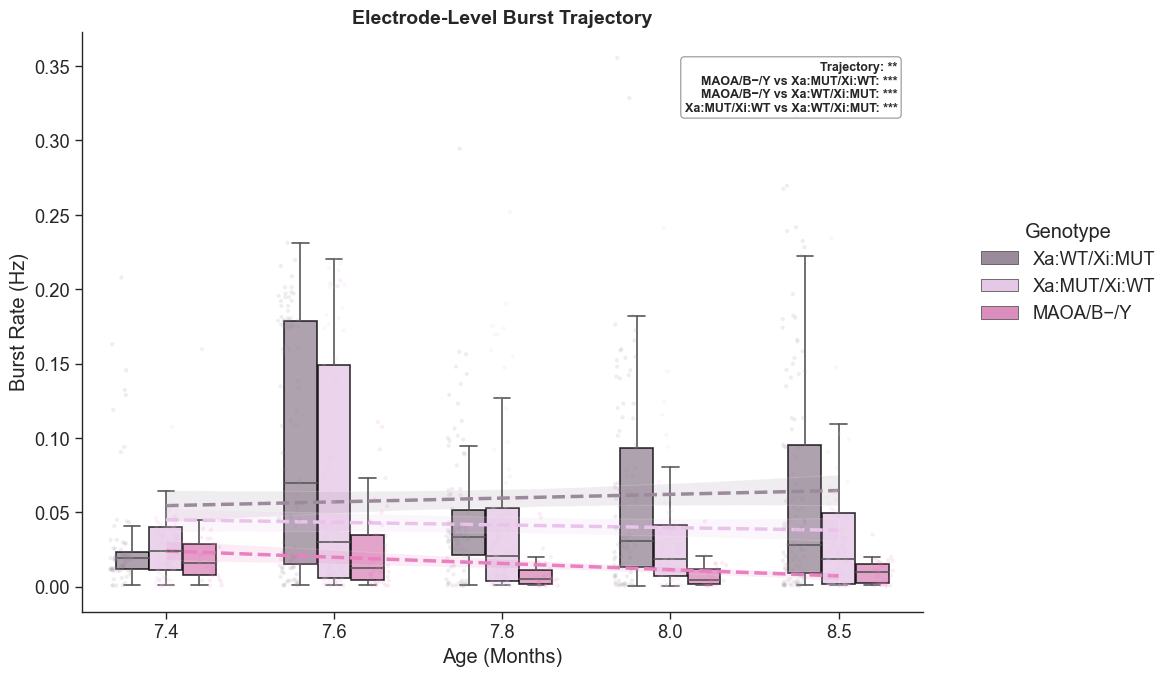


Trajectory ANOVA (Interaction):
                         sum_sq    df          F    PR(>F)
C(group)              0.018433   2.0  13.983767  0.000007
C(time_val)           0.003843   4.0   1.457755  0.224043
C(group):C(time_val)  0.006366   8.0   1.207302  0.307114
Residual              0.047455  72.0        NaN       NaN

Time-Point Comparisons:
  Time  ANOVA_p  MAOA/B−/Y vs Xa:MUT/Xi:WT (p-adj)  MAOA/B−/Y vs Xa:WT/Xi:MUT (p-adj)  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT (p-adj)
  7.4 0.774789                                NaN                                NaN                                   NaN
  7.6 0.085985                                NaN                                NaN                                   NaN
  7.8 0.025308                             0.1030                             0.0269                                0.5989
  8.0 0.061790                                NaN                                NaN                                   NaN
  8.5 0.001237                     

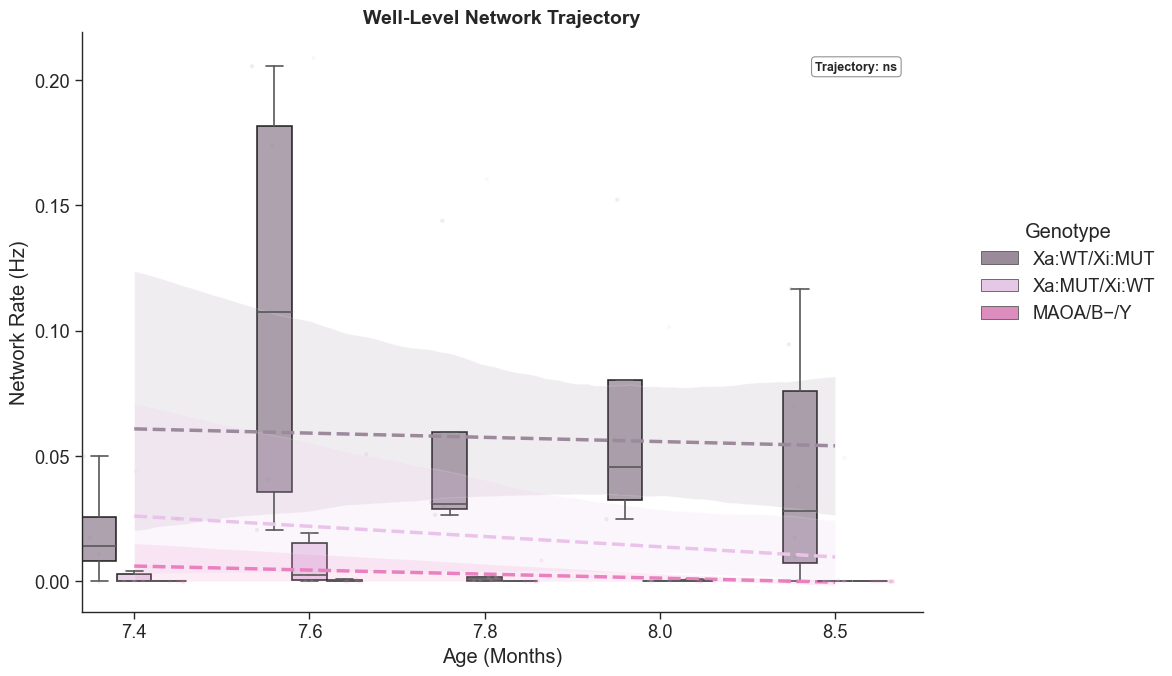


Trajectory ANOVA (Interaction):
                         sum_sq    df          F    PR(>F)
C(group)              0.044093   2.0  13.438953  0.000009
C(time_val)           0.014317   4.0   2.181752  0.078325
C(group):C(time_val)  0.010790   8.0   0.822156  0.585401
Residual              0.132880  81.0        NaN       NaN

Time-Point Comparisons:
  Time  ANOVA_p  MAOA/B−/Y vs Xa:MUT/Xi:WT (p-adj)  MAOA/B−/Y vs Xa:WT/Xi:MUT (p-adj)  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT (p-adj)
  7.4 0.361415                                NaN                                NaN                                   NaN
  7.6 0.112603                                NaN                                NaN                                   NaN
  7.8 0.237107                                NaN                                NaN                                   NaN
  8.0 0.049007                             0.7339                             0.0431                                0.1409
  8.5 0.000859                     

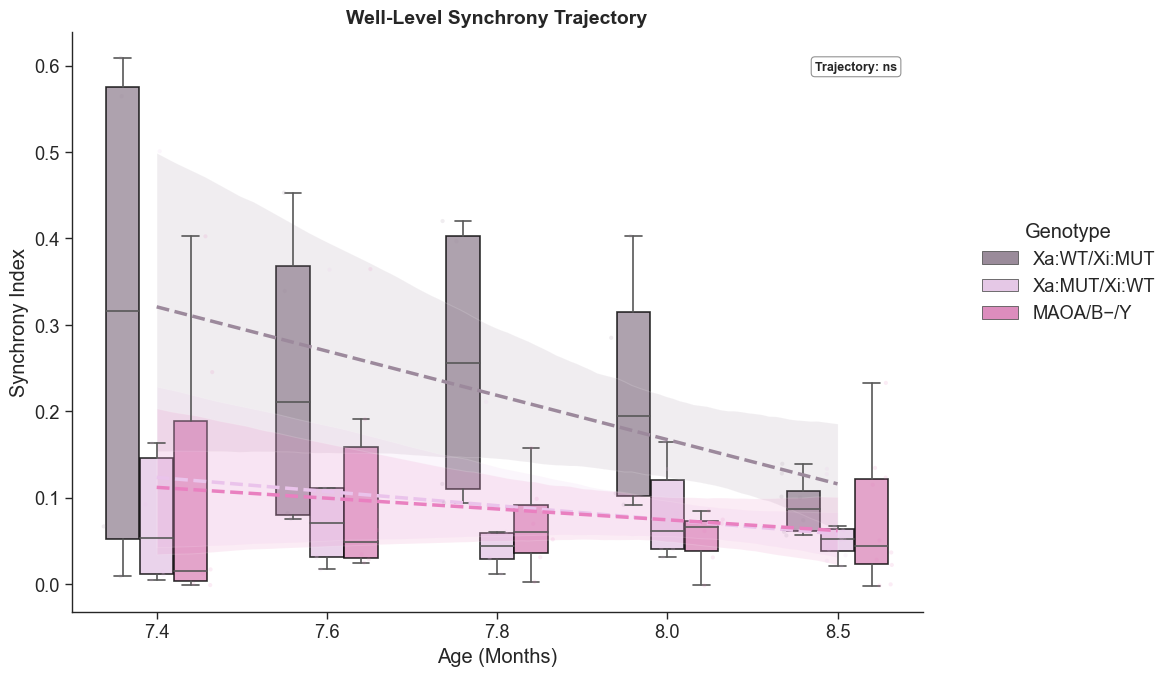


Trajectory ANOVA (Interaction):
                         sum_sq    df         F    PR(>F)
C(group)              0.248424   2.0  8.092525  0.000635
C(time_val)           0.120986   4.0  1.970592  0.107073
C(group):C(time_val)  0.091689   8.0  0.746699  0.650184
Residual              1.212570  79.0       NaN       NaN

Time-Point Comparisons:
  Time  ANOVA_p  MAOA/B−/Y vs Xa:MUT/Xi:WT (p-adj)  MAOA/B−/Y vs Xa:WT/Xi:MUT (p-adj)  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT (p-adj)
  7.4 0.353721                                NaN                                NaN                                   NaN
  7.6 0.380261                                NaN                                NaN                                   NaN
  7.8 0.021854                             0.9994                             0.0328                                0.0311
  8.0 0.019603                             0.8206                             0.0192                                0.0519
  8.5 0.468556                          

In [139]:
# You can pass your custom palette directly
my_stats = run_mea_analysis_for_figure(
    big_df, 
    experiment='Exp3', unit = "months",
    palette=MAOA_FIGURE_PALETTE
)